# The Goal:

-> Characterize low-level spikes or outliers;

-> Determining their bandwidth and corrupted channels;

-> Looking at the time occupancy of the low-level RFI spikes.

This step is perfome after the high level RFI idenfiend and masked from the raw data during the baseline correction.


In [1]:
# import the libraries
import h5py
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import cm, colors as mcolors



import scienceplots
plt.style.use(['science', 'no-latex'])


from pybaselines import Baseline, utils 
from scipy.signal import find_peaks
from scipy.stats import skew, kurtosis, gaussian_kde
from astropy.stats import median_absolute_deviation as MAD
from astropy.modeling import models, fitting
from astropy.convolution import convolve_models


# Read and convert to xarray

In [2]:

filename = ('/home/chavango/Master/DATA/SKAMPI_data/EDD_2023-03-11T14_58_01.567317UTC_ErQFG.hdf5')


# Let's porint the structure of the hdf5 file
def print_hdf5_structure(name, obj):
    indent = '  ' * name.count('/')
    if isinstance(obj, h5py.Group):
        print(f"{indent}Group: {name}")
    elif isinstance(obj, h5py.Dataset):
        print(f"{indent}Dataset: {name}, Shape: {obj.shape}, Dtype: {obj.dtype}")

with h5py.File(filename, "r") as f:

    f.visititems(print_hdf5_structure)

    f.close()  # close the file



Dataset: history, Shape: (9,), Dtype: [('processingtime', 'S23'), ('software', 'S256'), ('version', 'S128'), ('comment', 'S256')]
Group: monitor
  Group: monitor/acu
    Dataset: monitor/acu/actual_timestamp, Shape: (2650,), Dtype: float64
    Group: monitor/acu/ambient_temp_correction_config
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_1, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_10, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_2, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_3, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_4, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_5a, Shape: (2650,), Dtype: float64
      Dataset:

In [3]:

# Convert to xarray data set
groups = [
    "scan/000/P1_ND0",
    "scan/000/P1_ND1",
    "scan/001/P0_ND0",
    "scan/001/P0_ND1",
    "scan/001/P1_ND0",
    "scan/001/P1_ND1"
]


datasets = []

with h5py.File(filename, 'r') as f:
    for g in groups:
        
        # Load datasets correctly
        spectrum  = f[f"{g}/spectrum"][30:,1600:-60]       # shape (n_time, n_freq)
        frequency = f[f"{g}/frequency"][1600:-60]/ 1e9
        time      = f[f"{g}/timestamp"][30:,0]     # often 2D


        # Construct xarray dataset
        ds = xr.Dataset(
            {
                "spectrum": (("time", "frequency"), spectrum)
            },
            coords={
                "time": time,
                "frequency": frequency
            },
            attrs={
                "description": f"Spectrum data of {g}",
                "units": {
                    "spectrum": "dB",
                    "frequency": "GHz",
                    "time": "UTC"
                }
            }
        )

        ds = ds.expand_dims({"group": [g]})  # add group dimension

        datasets.append(ds)
    f.close() # close the file

datasets

[<xarray.Dataset> Size: 163MB
 Dimensions:    (group: 1, time: 634, frequency: 63877)
 Coordinates:
   * group      (group) object 8B 'scan/000/P1_ND0'
   * time       (time) float64 5kB 1.679e+09 1.679e+09 ... 1.679e+09 1.679e+09
   * frequency  (frequency) float64 511kB 1.793 1.793 1.793 ... 3.498 3.498 3.498
 Data variables:
     spectrum   (group, time, frequency) float32 162MB 1.883e+11 ... 4.159e+09
 Attributes:
     description:  Spectrum data of scan/000/P1_ND0
     units:        {'spectrum': 'dB', 'frequency': 'GHz', 'time': 'UTC'},
 <xarray.Dataset> Size: 163MB
 Dimensions:    (group: 1, time: 634, frequency: 63877)
 Coordinates:
   * group      (group) object 8B 'scan/000/P1_ND1'
   * time       (time) float64 5kB 1.679e+09 1.679e+09 ... 1.679e+09 1.679e+09
   * frequency  (frequency) float64 511kB 1.793 1.793 1.793 ... 3.498 3.498 3.498
 Data variables:
     spectrum   (group, time, frequency) float32 162MB 6.967e+10 ... 1.648e+09
 Attributes:
     description:  Spectrum da

In [4]:
# baseline substraction
def base_correction(freq,power):
    """ 
    The function perform the baseline correction using the method: "Asymmetric Least Squer"

    Takes as entries:
    --------
    freq: array
    power: array

    Returns:
    ------
    The signal with the baseline corrected
    
    """

    # Step 1: define the baseli fitting
    baseline_fitter = Baseline(x_data=freq)
    bkg, params = baseline_fitter.asls(power, lam=1e7, p=0.02)

    # Step 2: Substract the baseline
    correct_baseline = power - bkg

    return correct_baseline

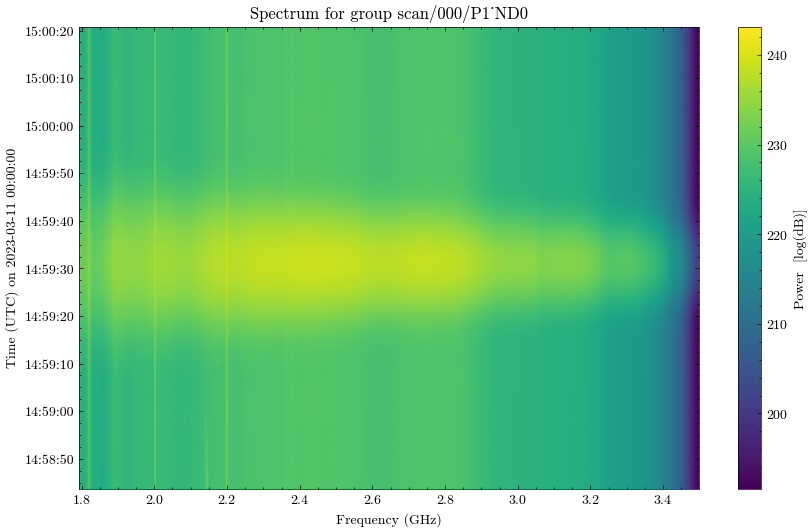

In [ ]:
# define the variablues

for i,g in enumerate(datasets):
    spectrum = (10*np.log10(datasets[i]['spectrum']**2)).values[0, :,:]
    time = datasets[i]['time'].values
    frequency = datasets[i]['frequency'].values

    # Date
    time_utc = pd.to_datetime(time, unit='s', origin='unix', utc=True)
    date =  pd.to_datetime(time_utc[0].strftime('%Y-%m-%d'))
    plt.figure(figsize=(10, 6))

    plt.imshow(spectrum, aspect='auto', 
    extent=[frequency[0], frequency[-1], time_utc[0], time_utc[-1]],
    origin='lower', cmap='viridis')

    plt.colorbar(label='Power  [dB]')
    plt.ylabel(f'Time (UTC) on {date}')
    plt.xlabel('Frequency (GHz)')
    plt.title(f'Spectrum for group {datasets[i].group.values[0]}')
    plt.show()

    break

In [6]:
spectrum.shape, time.shape, frequency.shape

((634, 63877), (634,), (63877,))

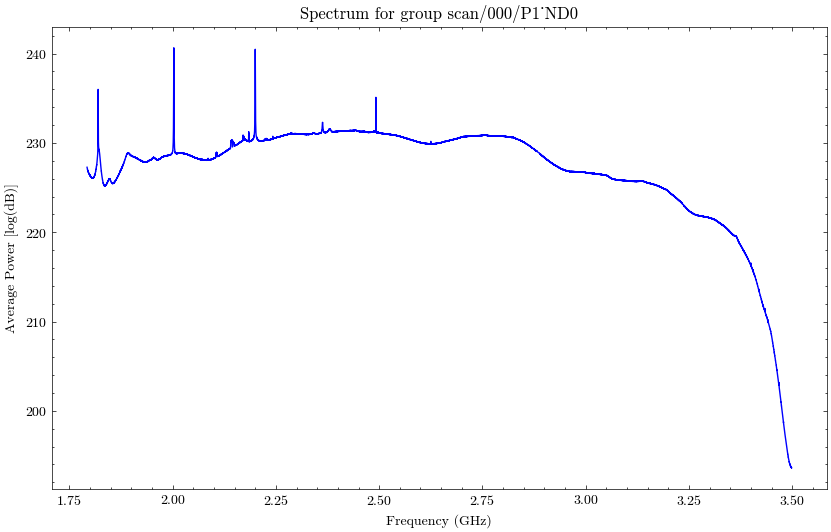

In [ ]:
# Average the spectrum over time
for i,g in enumerate(datasets):
    spectrum_mean = np.mean(10*np.log10(datasets[i]['spectrum']**2), axis=1).values[0, :]
    frequency = datasets[i]['frequency'].values

    plt.figure(figsize=(10, 6))
    plt.plot(frequency, spectrum_mean, color='blue')
    plt.ylabel(f'Average Power [dB]')
    plt.xlabel('Frequency (GHz)')
    plt.title(f'Spectrum for group {datasets[i].group.values[0]}')
    plt.show()

    break

In [8]:
# Isolate the skipe high prominent RFI signals

mask1 = (frequency > 1.8162) & (frequency < 1.8272) # IMT1800 BTX (Cellphone Downlink) GSM 1800
mask2 = (frequency > 1.8735) & (frequency < 1.8737) # IMT1800 BTX (Cellphone Downlink) GSM 1800
mask3 = (frequency > 2.0004) & (frequency < 2.0052) # Mobile Satellite Uplink (Earth to Space)
mask4 = (frequency > 2.0920) & (frequency < 2.0959) # Space Operations (Earth to Space and vice versa)
mask5 = (frequency > 2.1975) & (frequency < 2.2024) # Mobile Satellite Downlink (Space to Earth)
mask6 = (frequency > 2.3605) & (frequency < 2.3658) # Fixed Wireless Access Point to Point/Point to Multipoint #5G
mask7 = (frequency > 2.4916) & (frequency < 2.4925) # Mobile Satellite Services # ITU Resolution 249 (Rev.WRC‑23);
mask8 = (frequency > 2.6250) & (frequency < 2.6250) # ICASA (Independent Communications Authority of South Africa) Frequency Plan ???

mask = mask1 | mask2 | mask3 | mask4 | mask5 | mask6 | mask7 | mask8

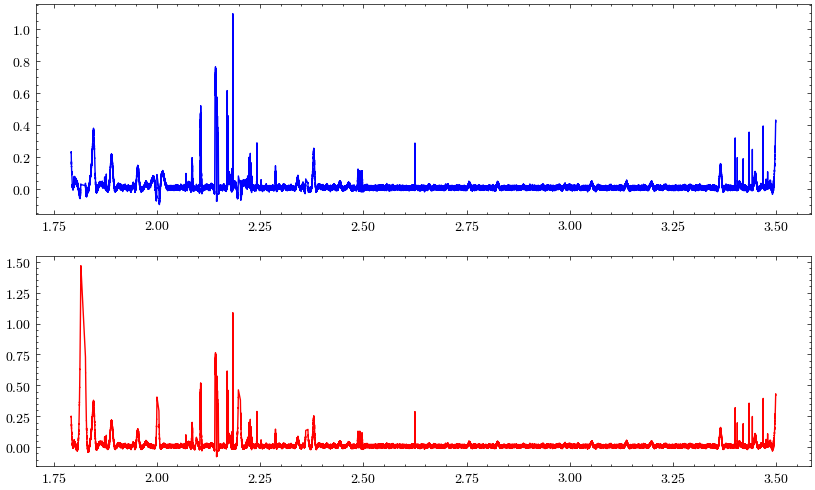

In [9]:
# detrend the spectrum 
detrended_avg_spectrum = base_correction(frequency, spectrum_mean)
detrended_avg_spectrum2 = base_correction(frequency[~mask], spectrum_mean[~mask])

fig, ax = plt.subplots(2,1, figsize=(10, 6))
ax[0].plot(frequency[~mask], detrended_avg_spectrum[~mask], color='blue')
ax[1].plot(frequency[~mask], detrended_avg_spectrum2, color='red')

# Peak detection

Detected peak > 1σ are frequencies (GHz): ['1.8468', '1.8778', '1.8903', '1.9539', '1.9912', '2.0004', '2.0143', '2.0706', '2.0855', '2.1057', '2.1064', '2.1067', '2.1071', '2.1074', '2.1421', '2.1424', '2.1434', '2.1440', '2.1459', '2.1703', '2.1707', '2.1715', '2.1723', '2.1727', '2.1823', '2.1827', '2.1833', '2.1841', '2.1845', '2.1849', '2.1975', '2.2233', '2.2264', '2.2274', '2.2285', '2.2425', '2.2873', '2.3417', '2.3800', '2.4871', '2.4916', '2.4969', '2.6250', '3.3647', '3.4003', '3.4054', '3.4196', '3.4340', '3.4418', '3.4485', '3.4680', '3.4788']


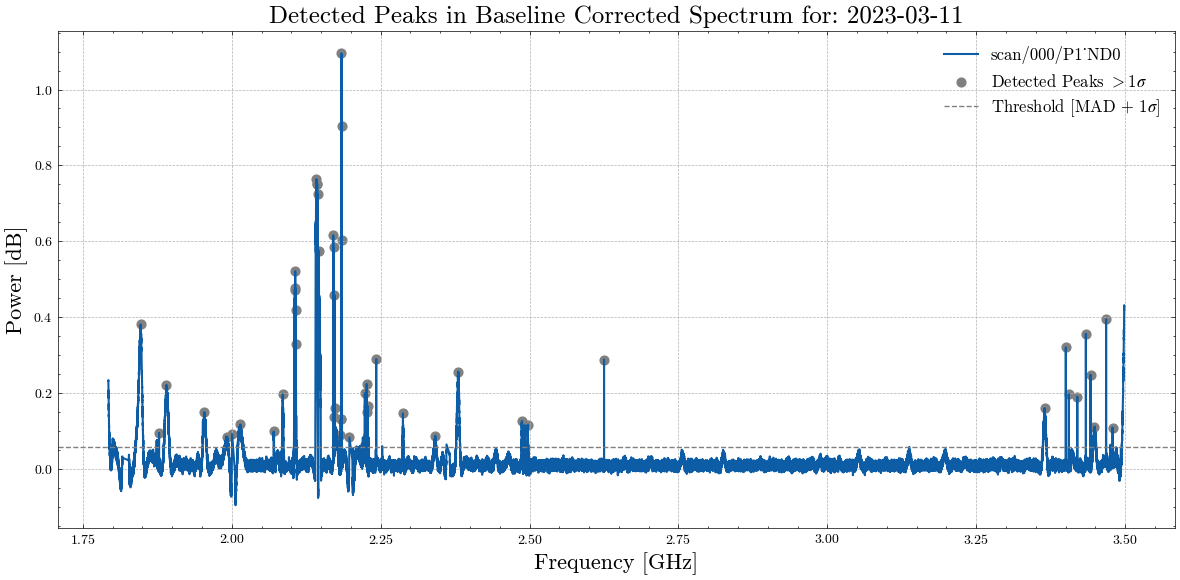

In [10]:
# # Base line corrected and peaks detection
for i,g in enumerate(datasets):
    
    avg_spectrum = (10* np.log10(datasets[i]['spectrum']**2)).mean(dim='time').values[0,:]
    detrended_spectrum = base_correction(frequency, avg_spectrum)
        
    # Find peaks above 1 sigma from the MAD
    peaks, propreties = find_peaks(detrended_spectrum[~mask], 
                                height=MAD(detrended_spectrum[~mask]) + np.std(detrended_spectrum[~mask]),
                                distance=10,
                                prominence=0.1
                                )
    # Find peaks above 3 sigma from the MAD
    peaks1, propreties1 = find_peaks(detrended_spectrum[~mask], 
                                height=MAD(detrended_spectrum[~mask]) + 3*np.std(detrended_spectrum[~mask]),
                                distance=10,
                                prominence=0.5
                                )

    plt.figure(figsize=(12, 6))

    freq = frequency[~mask]
    det_spec_masked = detrended_spectrum[~mask]

    # --- Plot baseline-corrected spectrum ---
    plt.plot(freq, det_spec_masked, label=f'{datasets[i].group.values[0]}', lw=1.5)

    # --- Plot detected peaks ---
    plt.scatter(freq[peaks], det_spec_masked[peaks], 
                color='gray', s=40, label='Detected Peaks $> 1σ$')

    # plt.scatter(freq[peaks1], det_spec_masked[peaks1], 
    #             color='red', s=50, label='Detected Peaks $> 3σ$')

    # --- Plot threshold lines ---
    plt.axhline(y=MAD(det_spec_masked) + np.std(det_spec_masked), 
                color='gray', linestyle='--', label='Threshold [MAD + 1$σ$]')

    # plt.axhline(y=MAD(det_spec_masked) + 3*np.std(det_spec_masked), 
    #         color='red', linestyle='--', label='Threshold [MAD + 3$σ$]')

    # --- Labels and formatting ---
    plt.xlabel("Frequency [GHz]",fontsize=16)
    plt.ylabel("Power [dB]",fontsize=16)
    plt.title(f"Detected Peaks in Baseline Corrected Spectrum for: {time_utc[0].strftime('%Y-%m-%d')}", fontsize=18)
    plt.grid(True, linestyle='--')
    plt.legend(fontsize=12)
    plt.tight_layout()

   #plt.savefig(f'/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Plots/Detected_Peaks_base_cor.png', dpi=300)
   #plt.savefig(f'/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Plots/Detected_Peaks_base_cor.pdf', dpi=300)


    # --- Print detected peak frequencies ---
    formatted_freqs = [f"{f:.4f}" for f in freq[peaks]]
    #formatted_freqs1 = [f"{f:.4f}" for f in freq[peaks1]]

    print(f"Detected peak > 1σ are frequencies (GHz): {formatted_freqs}")
    #print(f"Detected peak > 3σ are frequencies (GHz): {formatted_freqs1}")
    
    break


## Note

The average over time is not a good approach to evaluate the outliers

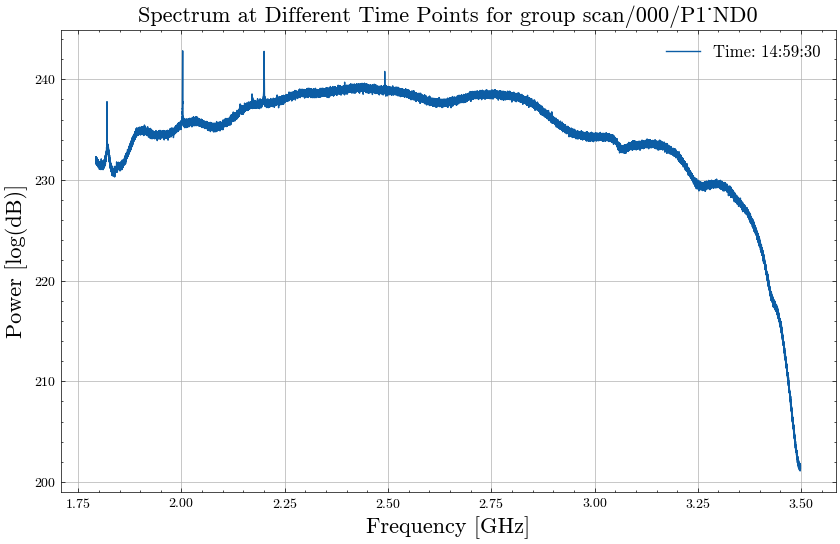

In [ ]:
# selecteting a time 

time_source = pd.to_datetime(["2023-03-11 14:59:30+00:00"])
# find nearest time index
moment = time_utc.get_indexer(time_source, method='nearest')
#itime

# #extract the spectrum at the nearest time index

plt.figure(figsize=(10, 6))
for t in moment:
    spectrum_source = spectrum[t, :]
    plt.plot(frequency, spectrum_source, label=f'Time: {time_utc[t].strftime("%H:%M:%S")}')


plt.xlabel('Frequency [GHz]', fontsize=16)
plt.ylabel('Power [dB]', fontsize=16)
plt.title(f'Spectrum at Different Time Points for group {datasets[i].group.values[0]}', fontsize=16)
plt.legend(fontsize=12)
plt.grid()

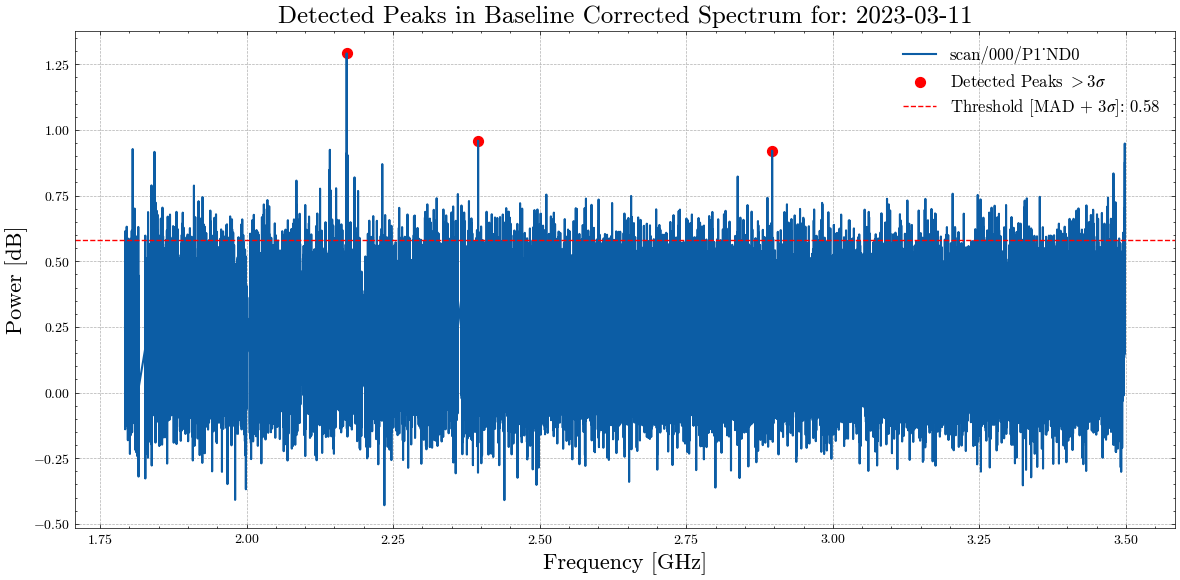

In [12]:
# detrending the spectrum

detrended_spectrum_source = base_correction(frequency, spectrum_source)
    
# Find peaks above 1 sigma from the MAD
peaks, propreties = find_peaks(detrended_spectrum_source[~mask], 
                            height=MAD(detrended_spectrum_source[~mask]) + 3*np.std(detrended_spectrum_source[~mask]),
                            distance=100,
                            prominence=1.25
                            )

plt.figure(figsize=(12, 6))

freq = frequency[~mask]
det_spec_sou_masked = detrended_spectrum_source[~mask]

# --- Plot baseline-corrected spectrum ---
plt.plot(freq, det_spec_sou_masked, label=f'{datasets[i].group.values[0]}', lw=1.5)

# --- Plot detected peaks ---

plt.scatter(freq[peaks], det_spec_sou_masked[peaks], 
            color='red', s=50, label='Detected Peaks $> 3σ$')

# --- Plot threshold lines ---

y3=MAD(det_spec_sou_masked) + 3*np.std(det_spec_sou_masked)
plt.axhline(y3, 
        color='red', linestyle='--', label=f'Threshold [MAD + 3$σ$]: {y3:.2f}')

# --- Labels and formatting ---
plt.xlabel("Frequency [GHz]",fontsize=16)
plt.ylabel("Power [dB]",fontsize=16)
plt.title(f"Detected Peaks in Baseline Corrected Spectrum for: {time_utc[0].strftime('%Y-%m-%d')}", fontsize=18)
plt.grid(True, linestyle='--')
plt.legend(fontsize=12)
plt.tight_layout()


/tmp/ipykernel_3201921/2542677824.py:5: FutureWarning: 'S' is deprecated and will be removed in a future version, please use 's' instead.
  target_times = pd.date_range(start=time_utc[0], end=time_utc[-1], freq=f'{time_step}S')


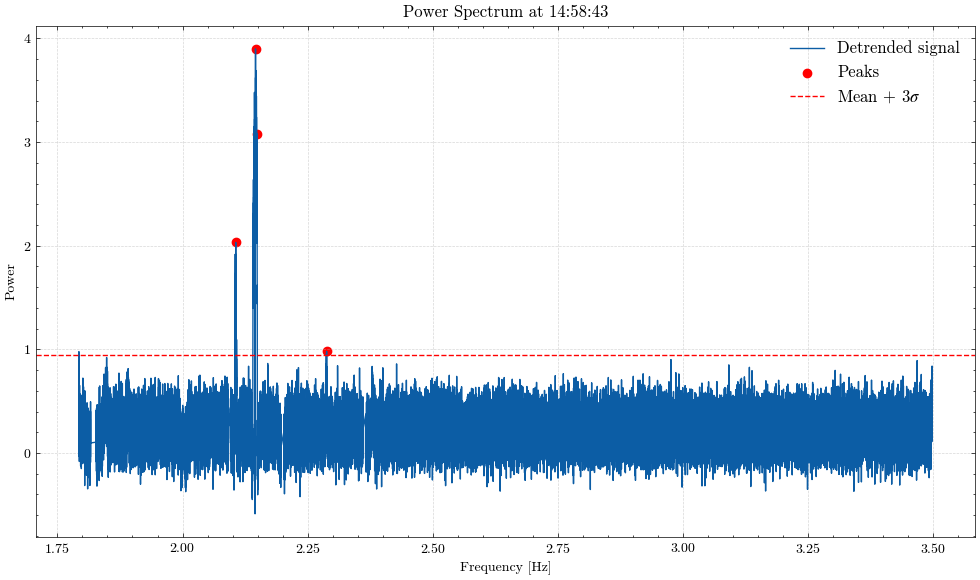

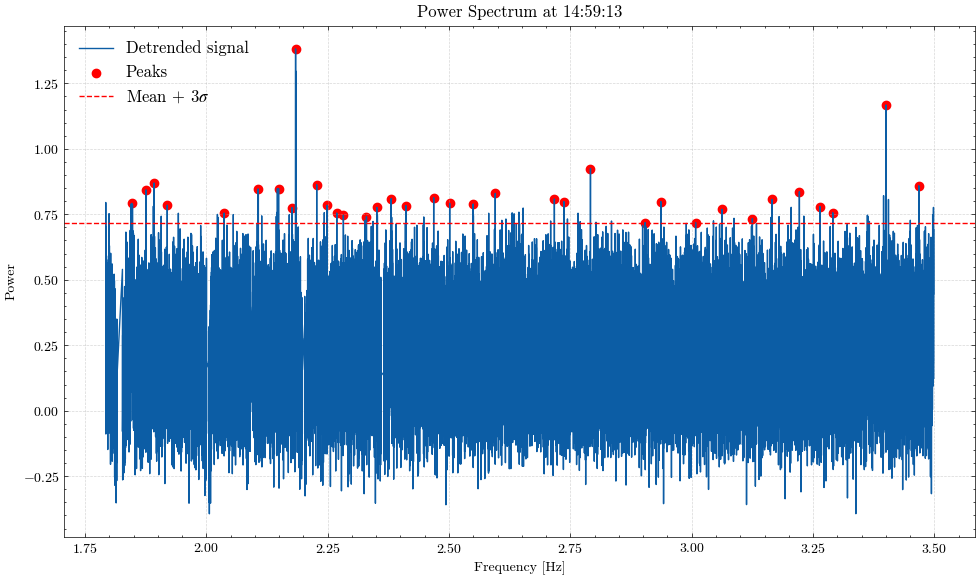

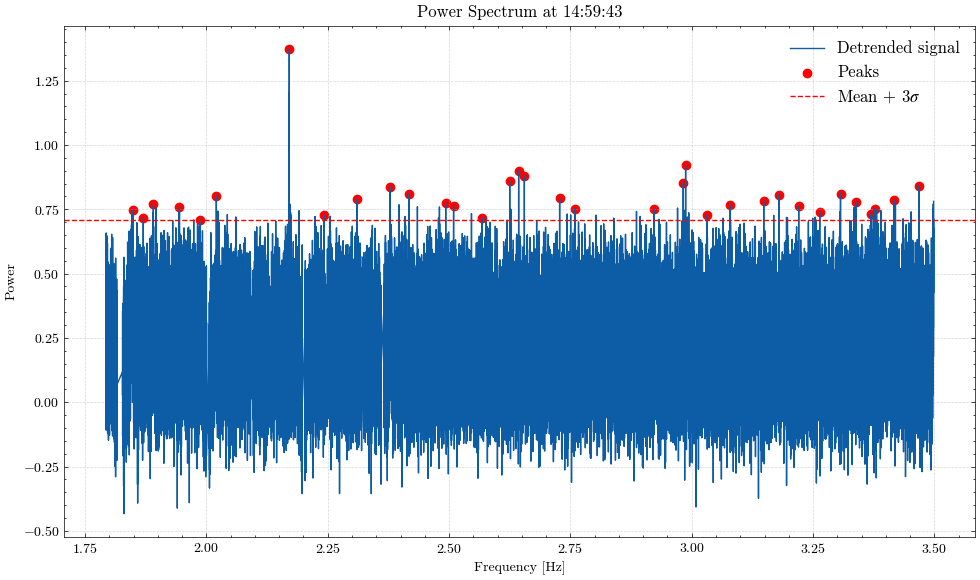

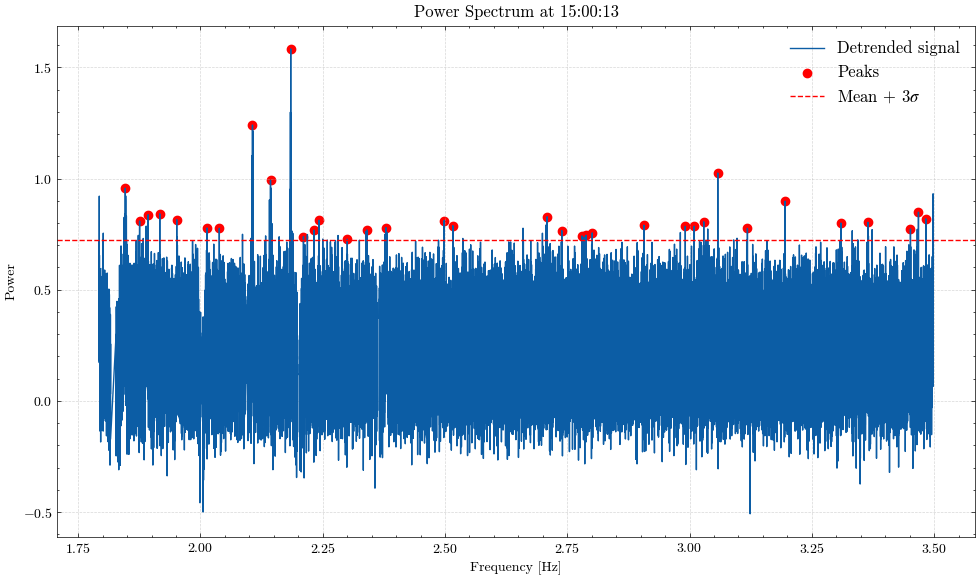

In [22]:

# Define your desired time step in seconds
time_step = 30  

# Select time indices with approximately 30-second spacing
target_times = pd.date_range(start=time_utc[0], end=time_utc[-1], freq=f'{time_step}S')

# Find nearest indices in your actual time_utc
itime_target = time_utc.get_indexer(target_times, method='nearest')


for i in itime_target:
    # Detrend / baseline correct the spectrum at this time
    det_spec_itime = base_correction(frequency, spectrum[i, :])

    # Mask bad frequencies
    freq_masked = frequency[~mask]
    det_spec_masked = det_spec_itime[~mask]

    # Detect peaks
    threshold = np.mean(det_spec_masked) + 3 * np.std(det_spec_masked)
    peaks, properties = find_peaks(det_spec_masked,
                                   height=threshold,
                                   prominence=1,
                                   distance=100)

    # Plot
    plt.figure(figsize=(10, 6))
    plt.plot(freq_masked, det_spec_masked, label='Detrended signal')
    plt.scatter(freq_masked[peaks], det_spec_masked[peaks], color='red', label='Peaks')
    plt.axhline(y=threshold, color='red', linestyle='--', label='Mean + $3σ$')

    plt.title(f'Power Spectrum at {time_utc[i].strftime("%H:%M:%S")}')
    plt.xlabel('Frequency [Hz]')
    plt.ylabel('Power')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend(fontsize=12)
    plt.tight_layout()
    plt.show()